In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_excel("Car_details_updated.xlsx")

df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,Torque,seats,RPM,Brand
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,190.0,5.0,2000.00,Maruti
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,250.0,5.0,2500.00,Skoda
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,12.7,5.0,3058.59,Honda
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,22.4,5.0,2750.00,Hyundai
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,11.5,5.0,3058.59,Maruti


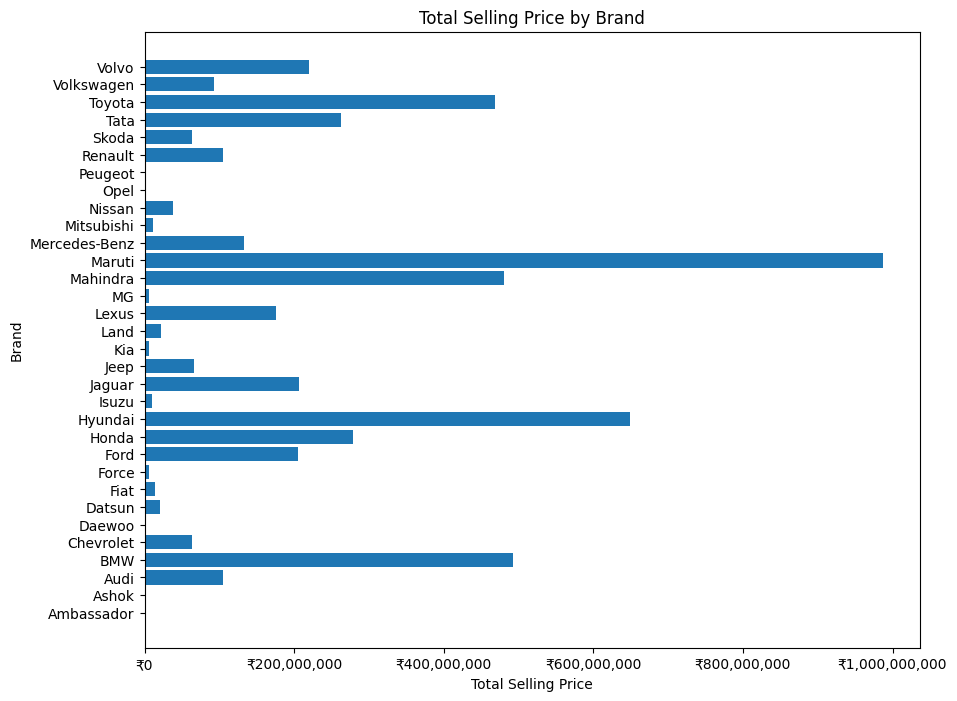

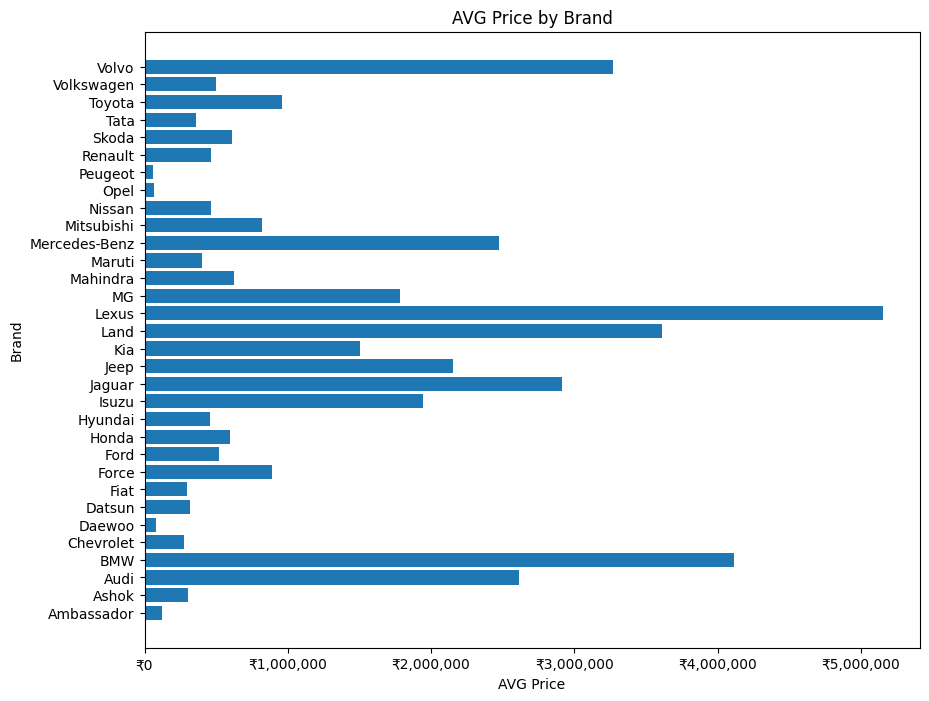

In [18]:
# Total Selling Prize by Brand 

from matplotlib.ticker import FuncFormatter

brand_sales = df.groupby("Brand")["selling_price"].sum()

plt.figure(figsize=(10, 8))
plt.barh(brand_sales.index, brand_sales.values)

plt.ylabel("Brand")
plt.xlabel("Total Selling Price")
plt.title("Total Selling Price by Brand")
plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'₹{x:,.0f}')
)
plt.show()

# AVG Selling Prize by Brand 

brand_sales = df.groupby("Brand")["selling_price"].mean()

plt.figure(figsize=(10, 8))
plt.barh(brand_sales.index, brand_sales.values)

plt.ylabel("Brand")
plt.xlabel("AVG Price")
plt.title("AVG Price by Brand")
plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'₹{x:,.0f}')
)
plt.show()

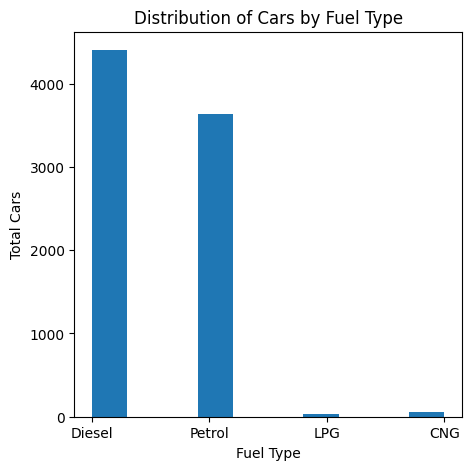

In [119]:
# Distribution of Cars by Fuel Type

plt.figure(figsize=(5,5))
plt.hist(df["fuel"], bins=10)
plt.title("Distribution of Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Total Cars")
plt.show()

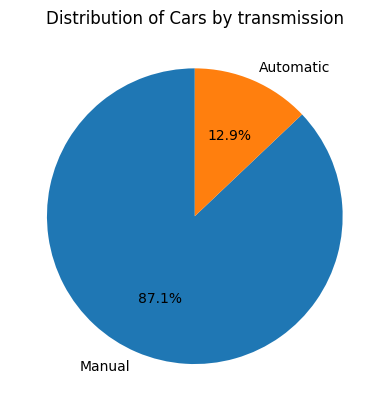

In [118]:
# Distribution of Cars by transmission
transmission = df["transmission"].value_counts()
plt.title("Distribution of Cars by transmission")
plt.pie(transmission.values, labels = transmission.index, autopct="%1.1f%%", startangle=90 )
plt.show()

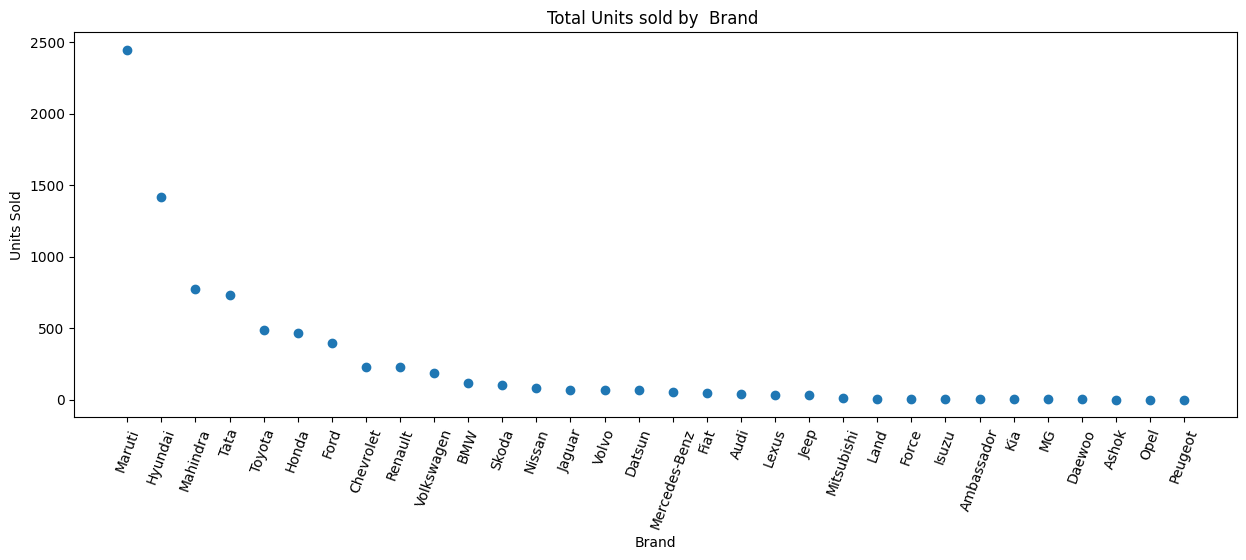

In [117]:
# Total Units sold by  Brand 
Brand = df["Brand"].value_counts()
plt.figure(figsize=(15,5))
plt.scatter(Brand.index, Brand.values)
plt.title("Total Units sold by  Brand ")
plt.xlabel("Brand")
plt.ylabel("Units Sold")
plt.xticks(rotation=70)
plt.show()

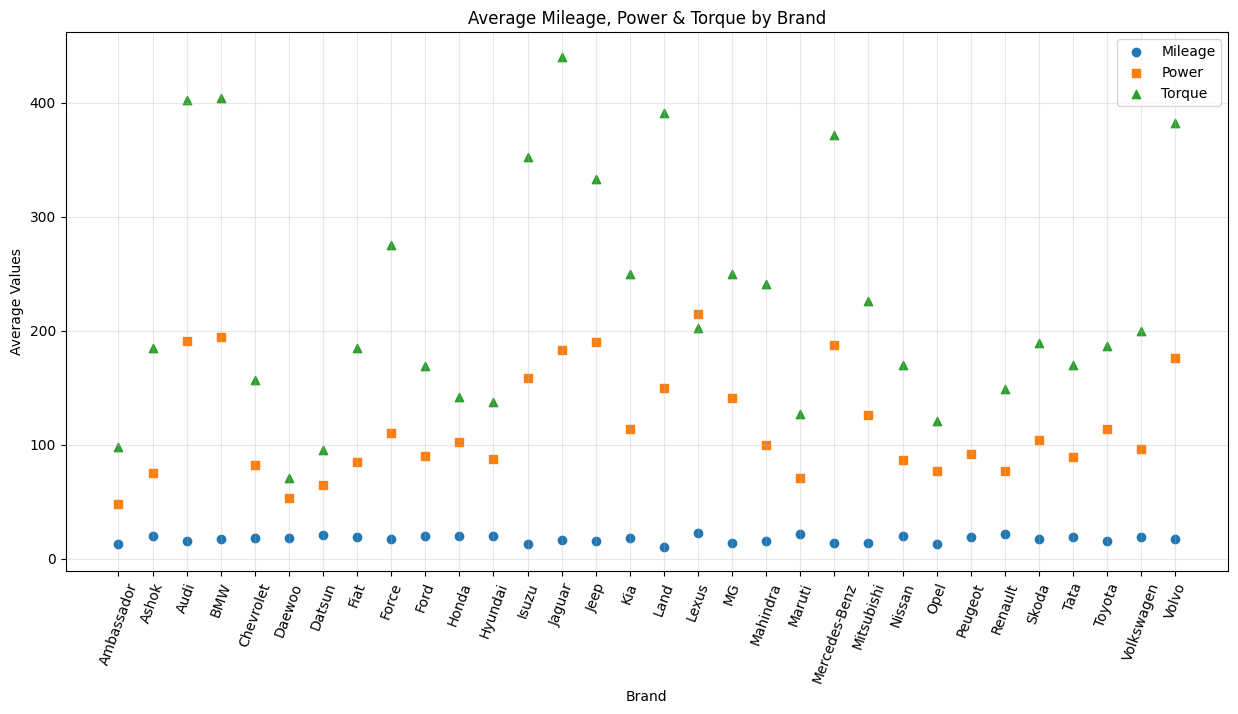

In [63]:
#Average Mileage, Power & Torque by Brand

avg_data = df.groupby("Brand")[["mileage", "max_power", "Torque"]].mean()

plt.figure(figsize=(15, 7))

plt.scatter(avg_data.index, avg_data["mileage"],
            label="Mileage", marker="o")

plt.scatter(avg_data.index, avg_data["max_power"],
            label="Power", marker="s")

plt.scatter(avg_data.index, avg_data["Torque"],
            label="Torque", marker="^")

plt.title("Average Mileage, Power & Torque by Brand")
plt.xlabel("Brand")
plt.ylabel("Average Values")
plt.xticks(rotation=70)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

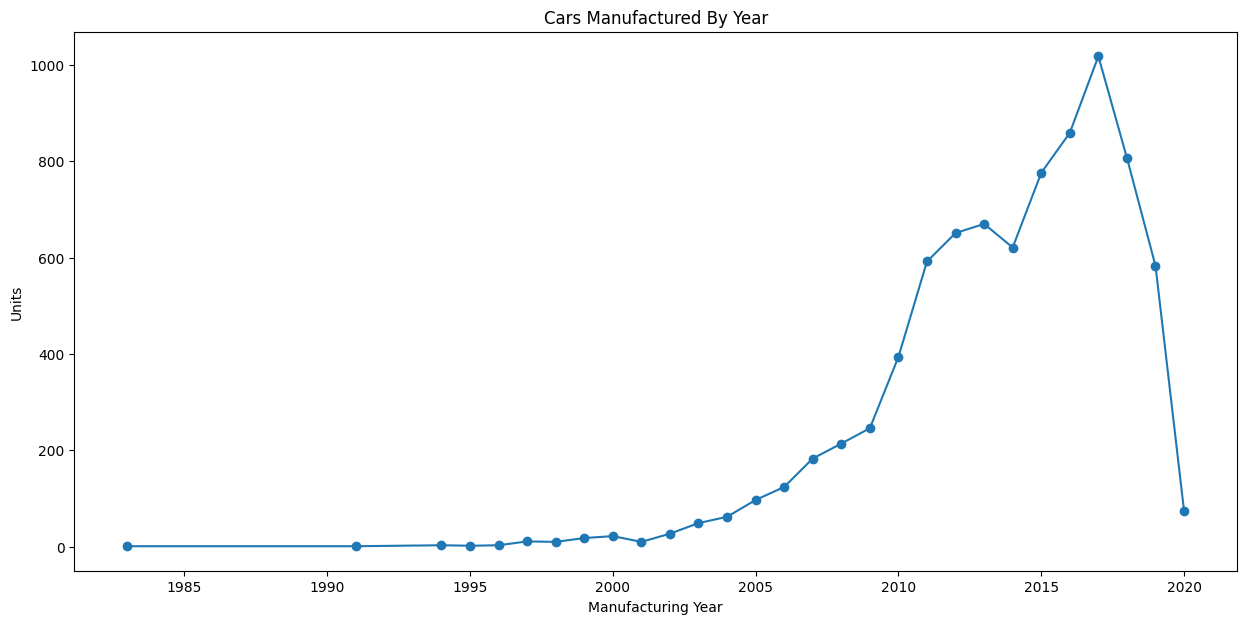

In [116]:
year = df.groupby("year").size().sort_index()

plt.figure(figsize=(15,7))
plt.plot(year.index,year.values,marker='o', linestyle='-')
plt.title("Cars Manufactured By Year")
plt.xlabel("Manufacturing Year")
plt.ylabel("Units")
plt.show()

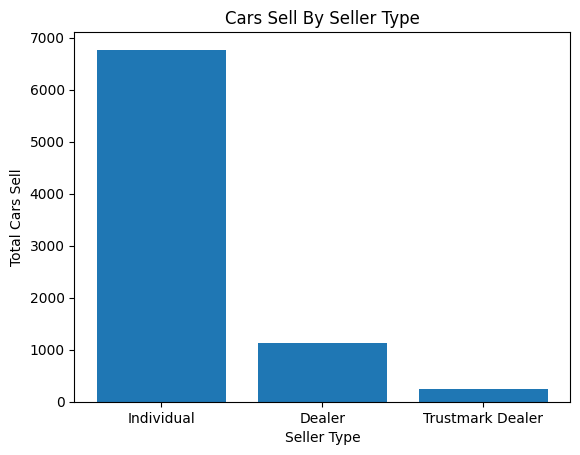

In [115]:
#Cars Sell By Seller Type
seller = df["seller_type"].value_counts()

plt.bar(seller.index,seller.values)
plt.title("Cars Sell By Seller Type")
plt.xlabel("Seller Type")
plt.ylabel("Total Cars Sell")
plt.show()

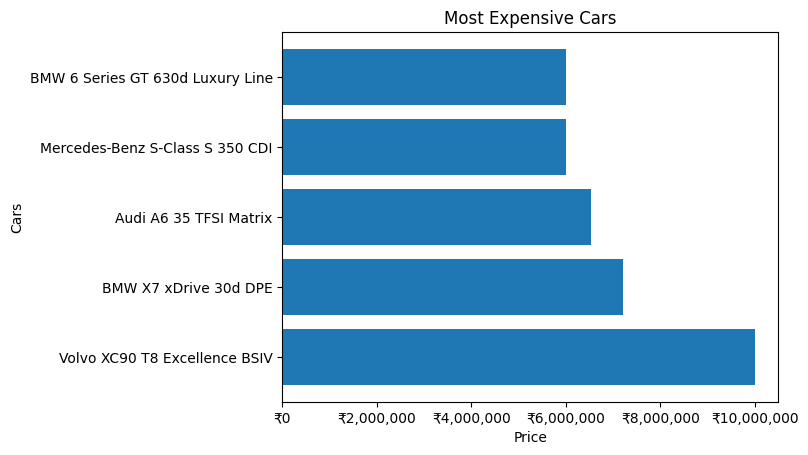

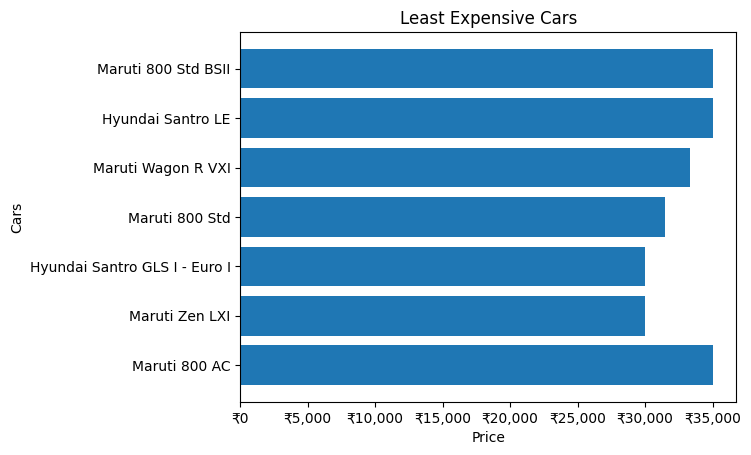

In [28]:
# 
from matplotlib.ticker import FuncFormatter
top = df.nlargest(10, "selling_price")
plt.barh(top["name"] , top["selling_price"])
plt.xlabel("Price")
plt.ylabel("Cars")
plt.title("Most Expensive Cars")
#plt.xticks(rotation=50)
plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'₹{x:,.0f}')
)
plt.show()
print()
print()
low = df.nsmallest(10, "selling_price")
plt.barh(low["name"] , low["selling_price"])
plt.xlabel("Price")
plt.ylabel("Cars")
plt.title("Least Expensive Cars")
#plt.xticks(rotation=40)
plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'₹{x:,.0f}')
)
plt.show()

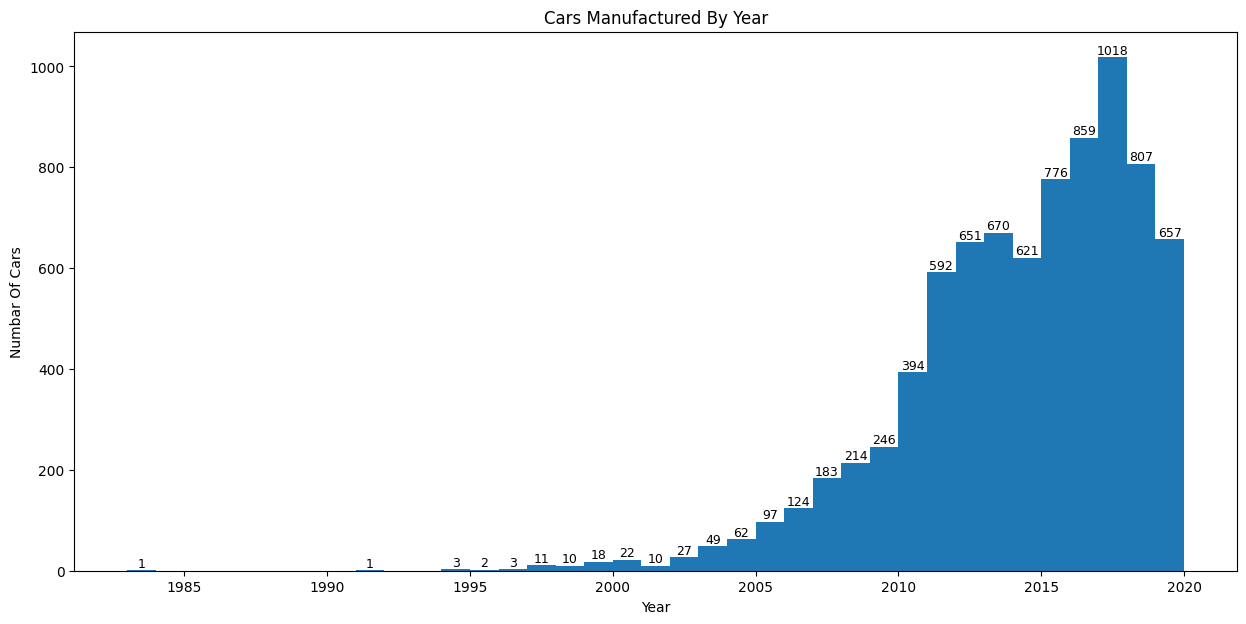

In [25]:

plt.figure(figsize=(15,7))
counts, bins, patches = plt.hist(df["year"], bins=37)
for count, patch in zip(counts, patches):
    if count > 0:
        plt.text(
            patch.get_x() + patch.get_width() / 2,
            count,
            int(count),
            ha="center",
            va="bottom",
            fontsize=9
        )
plt.xlabel("Year")
plt.ylabel("Numbar Of Cars")
plt.title("Cars Manufactured By Year")
plt.show()

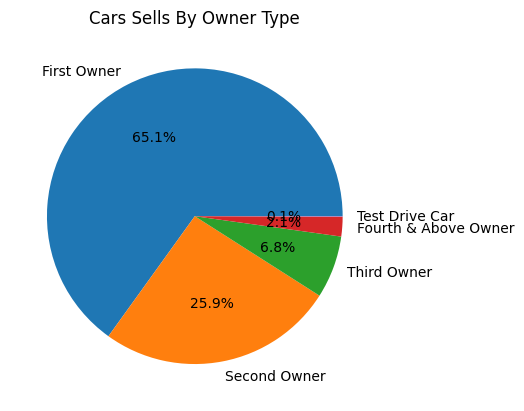

In [43]:

owner = df["owner"].value_counts()

plt.pie(owner.values, labels = owner.index, autopct= "%1.1f%%", startangle=0)
plt.title("Cars Sells By Owner Type")
plt.show()

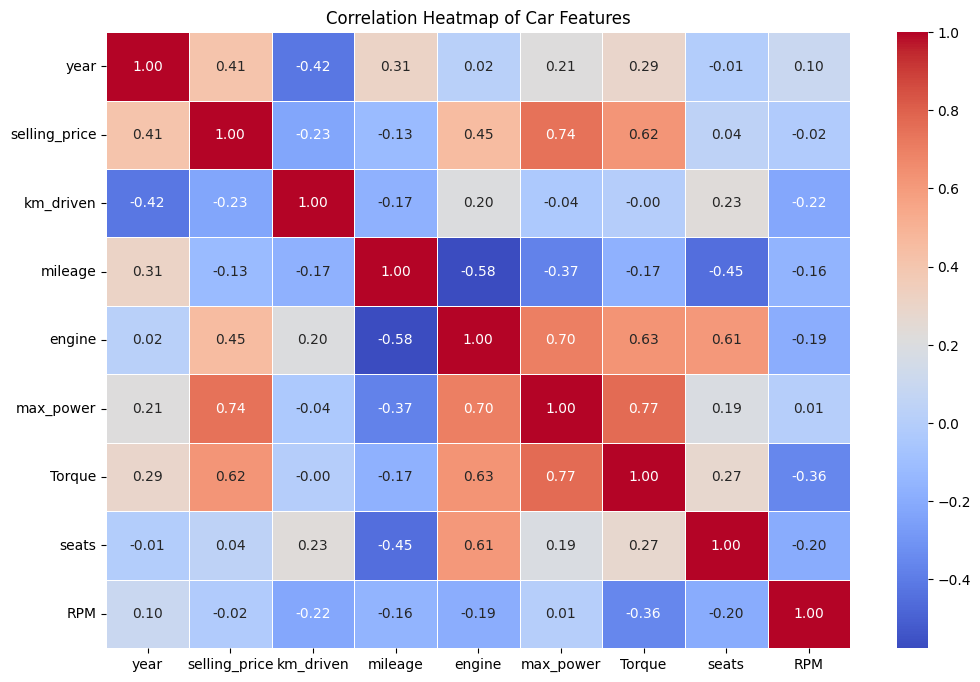

In [44]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Car Features")
plt.show()